# Issue #306 — matched-exposure within-issue ticket composition

Every eligible issue receives exactly 512 CNY2 tickets. The model cannot
improve by skipping an issue or shrinking its committed budget; it must learn
N, K, match/outcome sampling and WR/WOR composition. 2024+ is sealed.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'src' / 'issue306').is_dir())
OUTPUT = ROOT / 'results/issue-306'
decision = json.loads((OUTPUT / 'decision.json').read_text())
decision

{'issue': 306,
 'question': 'within-issue ticket construction at fixed issue coverage and exposure',
 'decision': {'verdict': 'ACTION_VALUE_SIGNAL',
  'promotable': False,
  'development_signal': True,
  'dynamic_ticket_signal': False,
  'eligible_issue_policy': 'ALL_ISSUES_ACTIVE_NO_LEARNED_SKIP',
  'committed_tickets_per_issue': 512,
  'committed_stake_per_issue_cny': 1024.0,
  'development_selected_primary': 'LEARNED_MEAN_DETERMINISTIC',
  'development_selection_metric': 'median cumulative 2021-2022 physical PnL across nuisance seeds',
  'development_candidate_pnl_cny': {'LEARNED_MEAN_DETERMINISTIC': -24983.854423494544,
   'LEARNED_TAIL_MIXTURE': -27545.045273934385,
   'LEARNED_TAIL_DETERMINISTIC': -37259.0604187107},
  'primary_2023_median_terminal_capital_cny': 101409.52998451988,
  'primary_2023_median_growth_pct': 1.409529984519886,
  'primary_2023_median_turnover_roi_pct': 2.5971587273729964,
  'primary_2023_median_max_drawdown_pct': 12.630201316165158,
  'primary_2023_median

## Action-surface coverage and fit receipts

In [2]:
coverage = pd.read_csv(OUTPUT / 'action_surface_coverage.csv')
display(coverage.groupby('issue_year').agg(issues=('issue','nunique'),
    min_feasible_actions=('feasible_actions','min'), max_missing_actions=('missing_actions','max')))
receipts = pd.read_csv(OUTPUT / 'fit_receipts.csv')
display(receipts.groupby('condition').agg(fits=('model_seed','size'),
    converged=('converged','all'), max_iterations=('iterations','max'),
    train_issues=('train_issues','max')))

,issues,min_feasible_actions,max_missing_actions
issue_year,,,
2019,53,96,0
2020,38,60,36
2021,63,96,0
2022,62,96,0
2023,53,96,0


,fits,converged,max_iterations,train_issues
condition,,,,
IDENTITY_SHUFFLED,15,False,500,216
ISSUE_BLOCK_SHUFFLED,15,True,455,216
LEARNED,15,True,409,216


## Fixed-coverage capital and tail comparison

,evaluation_year,condition,median_terminal_capital_cny,median_capital_growth_pct,median_turnover_roi_pct,median_max_drawdown_pct,median_ex_largest_pnl_cny,median_positive_issue_rate,median_tail_5x_rate,median_mean_distinct_actions
27,2021,ORACLE_DIAGNOSTIC,7.177510e+05,617.750960,957.575274,3.072000,365831.532373,0.317460,0.285714,1.000000
6,2021,FIXED_N7_K512_WEIGHTED_WOR,1.108117e+05,10.811659,16.759143,11.769816,3825.610060,0.269841,0.047619,1.000000
9,2021,FIXED_N7_K512_WEIGHTED_WR,8.856414e+04,-11.435860,-17.726718,26.560856,-20232.261974,0.238095,0.047619,1.000000
18,2021,LEARNED_MEAN_DETERMINISTIC,8.639171e+04,-13.608290,-21.094200,20.172951,-21281.856794,0.238095,0.015873,1.000000
24,2021,LEARNED_TAIL_MIXTURE,8.324802e+04,-16.751979,-25.967229,18.473265,-23288.372924,0.190476,0.015873,8.047619
15,2021,ISSUE_BLOCK_SHUFFLED,8.080174e+04,-19.198263,-29.759212,22.871536,-22693.825295,0.222222,0.000000,9.285714
30,2021,STATIC_TAIL_MIXTURE,7.994337e+04,-20.056631,-31.089768,20.155585,-25126.427080,0.269841,0.015873,10.000000
21,2021,LEARNED_TAIL_DETERMINISTIC,7.795022e+04,-22.049775,-34.179339,23.743699,-28948.349875,0.142857,0.047619,1.000000
12,2021,IDENTITY_SHUFFLED,6.506428e+04,-34.935716,-54.153825,37.180903,-37964.456878,0.126984,0.000000,11.809524
0,2021,BEST_STATIC_ACTION,3.548800e+04,-64.512000,-100.000000,64.512000,-63488.000000,0.000000,0.000000,1.000000


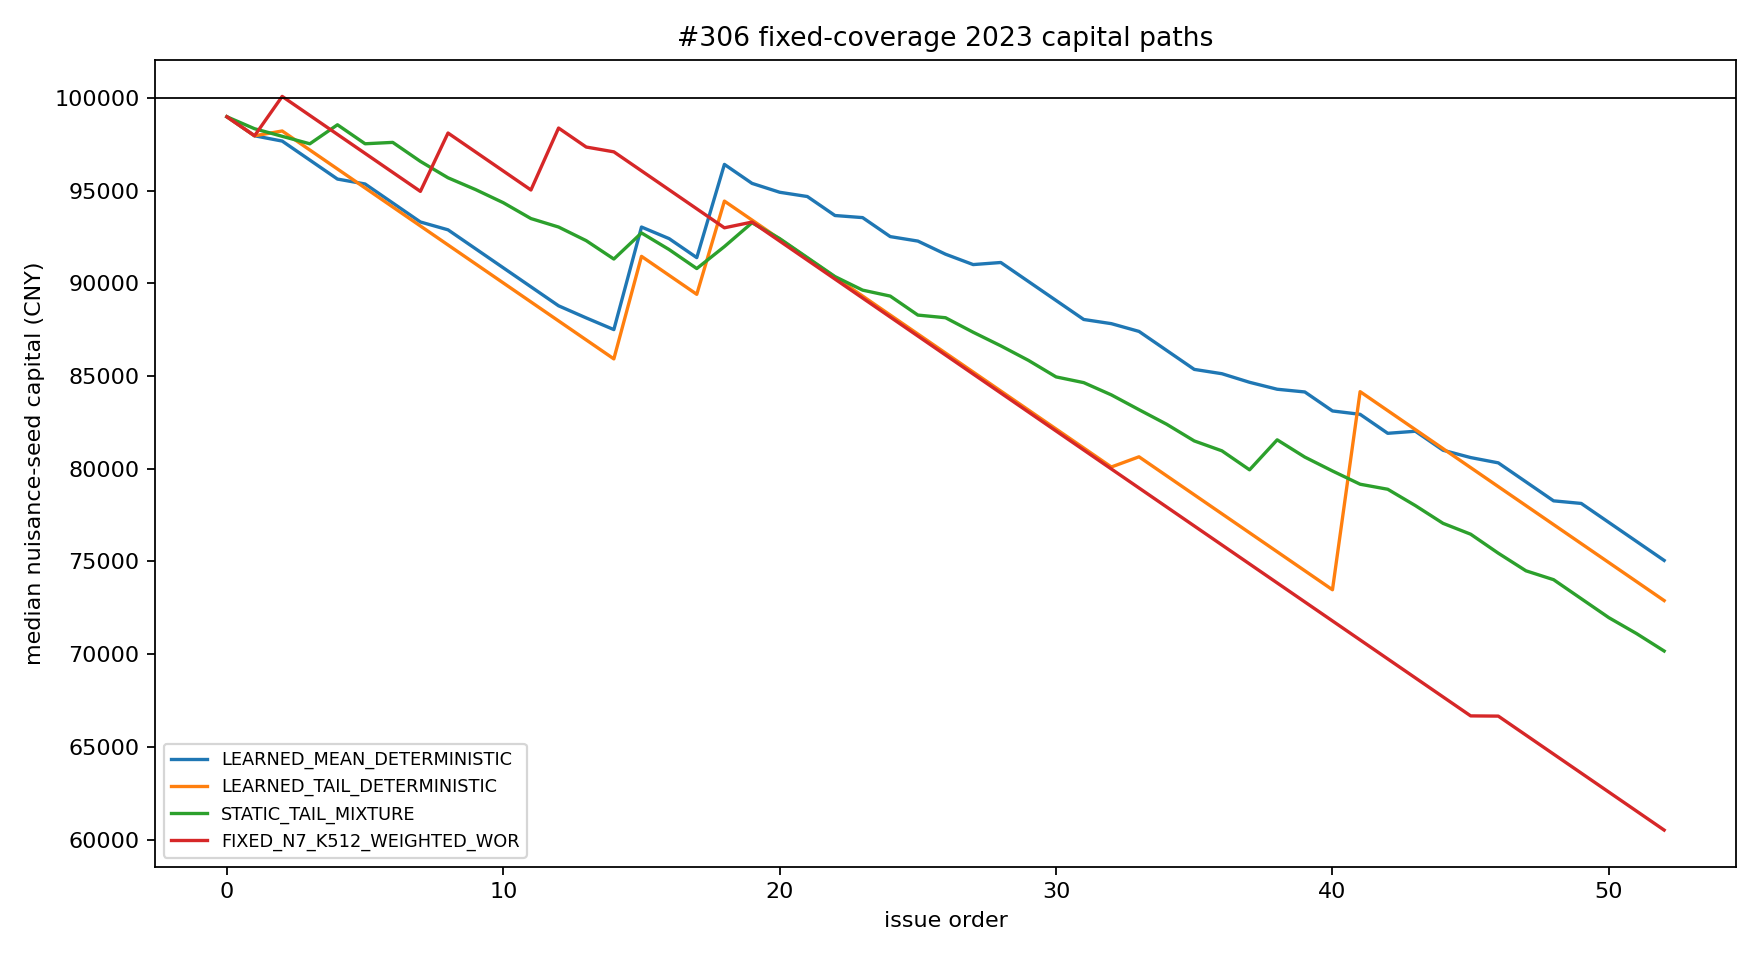

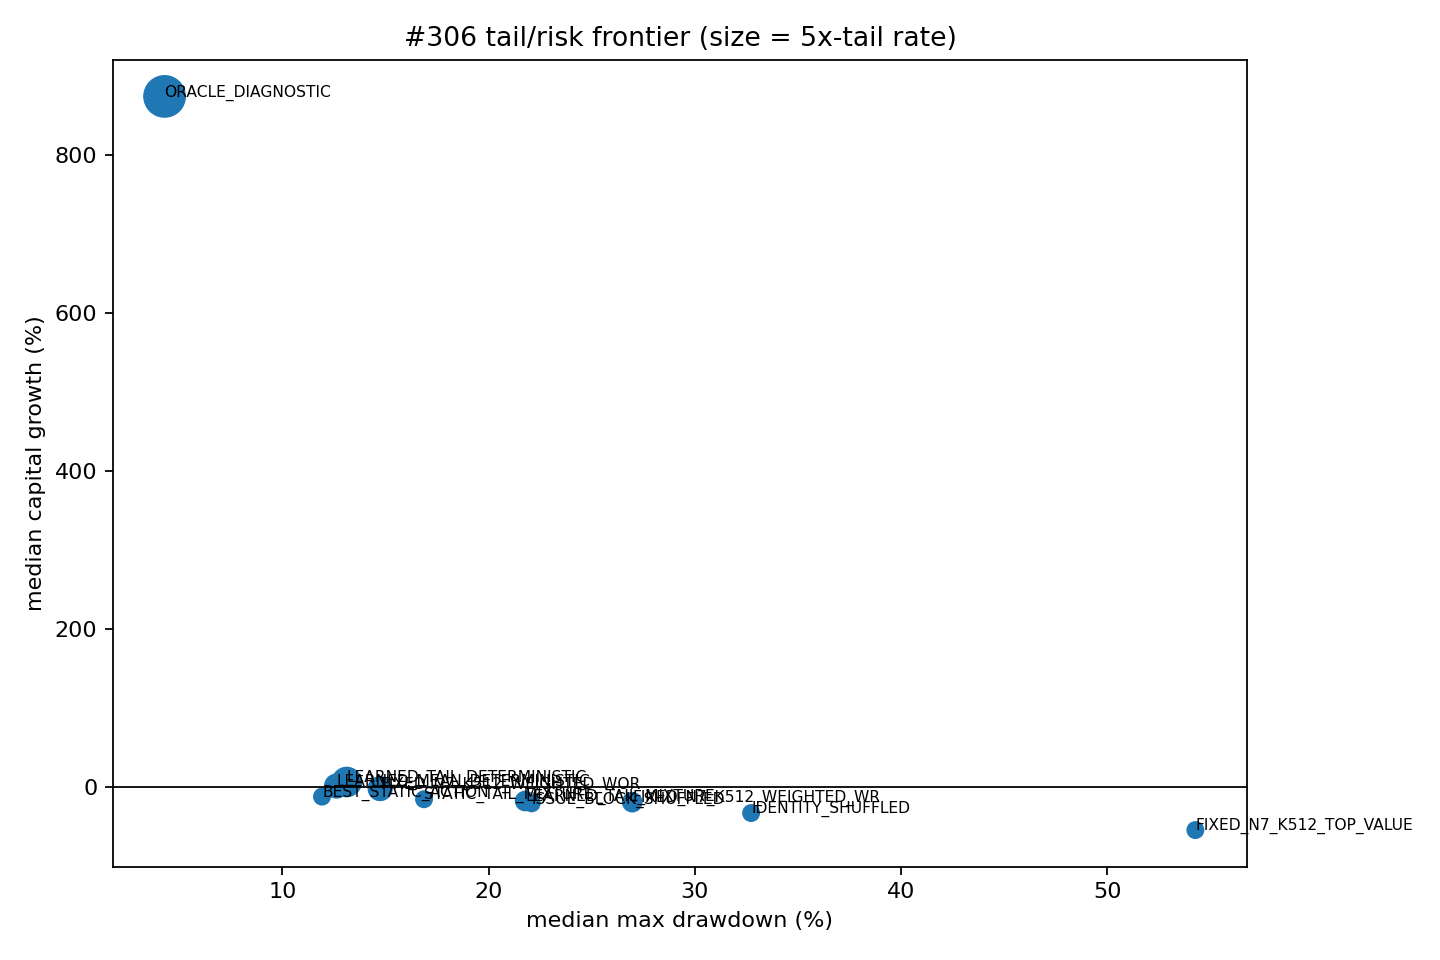

In [3]:
summary = pd.read_csv(OUTPUT / 'policy_summary.csv')
cols = ['evaluation_year','condition','median_terminal_capital_cny',
        'median_capital_growth_pct','median_turnover_roi_pct',
        'median_max_drawdown_pct','median_ex_largest_pnl_cny',
        'median_positive_issue_rate','median_tail_5x_rate',
        'median_mean_distinct_actions']
display(summary[cols].sort_values(['evaluation_year','median_terminal_capital_cny'], ascending=[True,False]))
display(Image(filename=str(OUTPUT / 'capital_paths_2023.png')))
display(Image(filename=str(OUTPUT / 'tail_risk_frontier_2023.png')))

## Learned parameter distribution and null

,condition,issue_year,n,k,generator,issues,action_rows,allocated_tickets
264,LEARNED_MEAN_DETERMINISTIC,2021,5,512,WEIGHTED_WR,14,14,7168
288,LEARNED_MEAN_DETERMINISTIC,2022,8,512,WEIGHTED_WOR,13,13,6656
261,LEARNED_MEAN_DETERMINISTIC,2021,4,128,WEIGHTED_WR,12,12,6144
279,LEARNED_MEAN_DETERMINISTIC,2022,3,512,WEIGHTED_WOR,10,10,5120
304,LEARNED_MEAN_DETERMINISTIC,2023,5,512,WEIGHTED_WR,10,10,5120
263,LEARNED_MEAN_DETERMINISTIC,2021,5,512,WEIGHTED_WOR,8,8,4096
289,LEARNED_MEAN_DETERMINISTIC,2022,8,512,WEIGHTED_WR,7,7,3584
280,LEARNED_MEAN_DETERMINISTIC,2022,3,512,WEIGHTED_WR,7,7,3584
293,LEARNED_MEAN_DETERMINISTIC,2023,3,128,TOP_VALUE,6,6,3072
296,LEARNED_MEAN_DETERMINISTIC,2023,3,512,TOP_VALUE,5,5,2560


,count,mean,std,min,5%,50%,95%,max
condition,,,,,,,,
LEARNED_MEAN_DETERMINISTIC,2000.0,82244.487136,8195.511838,63535.885594,69440.846875,81649.132006,96475.989315,113585.841120
LEARNED_TAIL_DETERMINISTIC,2000.0,83681.850786,10966.326459,53658.986282,66580.020303,83299.234041,102137.970036,124124.913160
LEARNED_TAIL_MIXTURE,2000.0,86984.575491,5083.944336,74431.708885,79245.657726,86564.906683,95825.829349,105698.618027


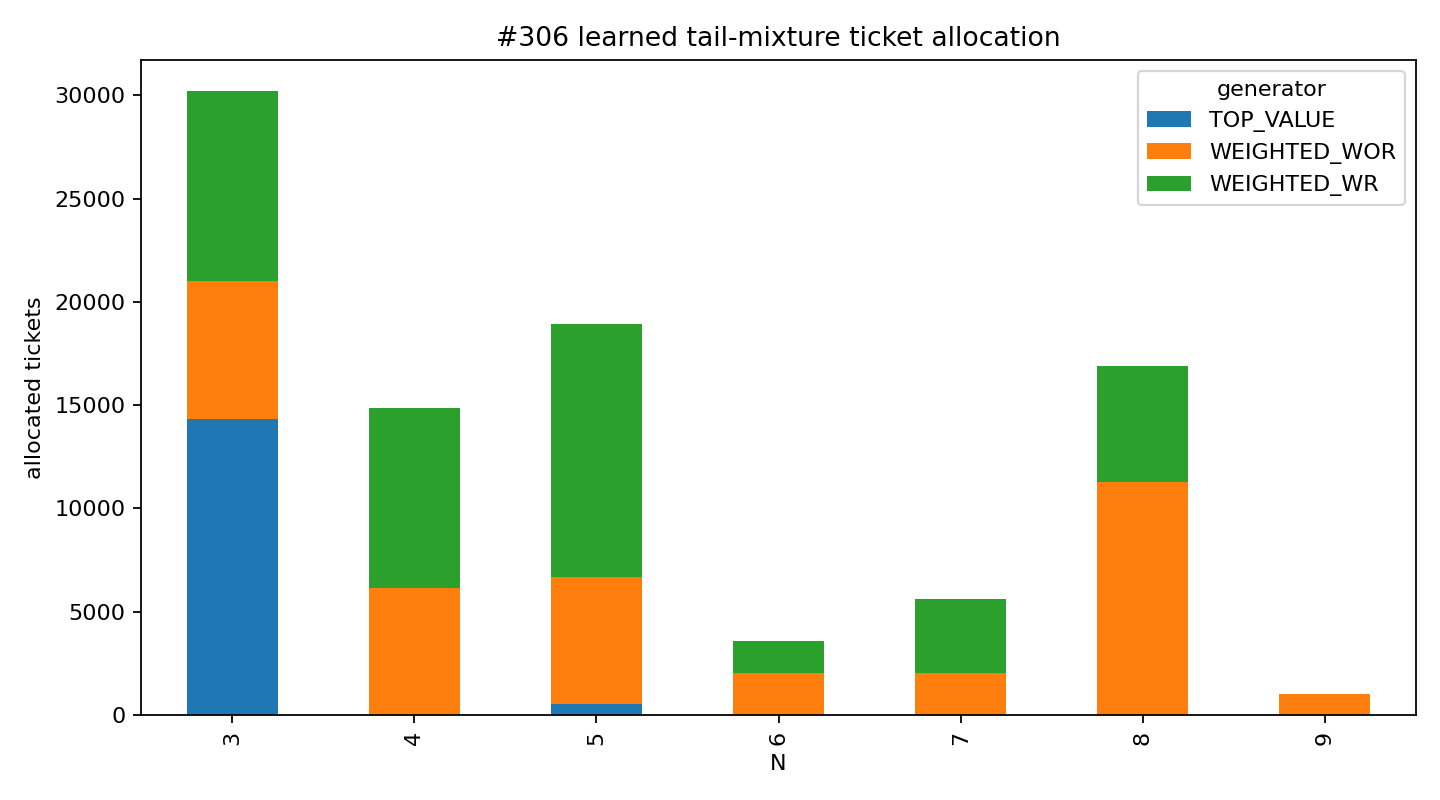

In [4]:
primary = decision['decision']['development_selected_primary']
actions = pd.read_csv(OUTPUT / 'action_distribution.csv')
display(actions[actions.condition.eq(primary)]
        .sort_values('allocated_tickets', ascending=False).head(30))
null = pd.read_csv(OUTPUT / 'same_exposure_permutation_2023.csv')
display(null.groupby('condition').median_terminal_capital_cny
        .describe(percentiles=[.05,.5,.95]))
display(Image(filename=str(OUTPUT / 'learned_action_distribution.png')))

## Interpretation

The decision payload and controls determine whether the learned composition
adds within-issue value. Any improvement caused only by cash, fewer issues or
less committed stake is structurally impossible in this experiment. The
outcome-aware oracle remains diagnostic and no 2024+ result is opened.